# 04 — OCR and page records

## Objective

Execute native, partial-OCR, and full-OCR extraction; inspect their differences; and assemble a transparent page record containing identity, routing evidence, extracted text, and a rendered page image.

## Concept

Partial OCR (`full=False`) preserves native text and OCRs the remaining visible content. Full OCR (`full=True`) renders and re-reads the entire page. Partial OCR is useful when a scan has a reliable native overlay; full OCR avoids trusting a misleading text layer. A page record keeps both the extraction decision and the evidence needed to audit it.

In [1]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pymupdf
from PIL import Image


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
DOCUMENTS_DIR = PROJECT_ROOT / "data" / "documents"
TESSDATA_DIR = PROJECT_ROOT / "resources" / "tessdata"

## Implementation — routing and extraction

The helper functions are repeated here intentionally so this notebook remains runnable from a fresh kernel without hidden cross-notebook state.

In [2]:
def inspect_page(page):
    words = page.get_text("words")
    images = page.get_image_info()
    page_area = page.rect.get_area()
    coverage = max(
        ((pymupdf.Rect(image["bbox"]) & page.rect).get_area() / page_area for image in images),
        default=0.0,
    )
    return {
        "native_words": len(words),
        "image_count": len(images),
        "largest_image_fraction": round(coverage, 3),
    }


def select_method(features, image_threshold=0.90, overlay_word_limit=20):
    words = features["native_words"]
    coverage = features["largest_image_fraction"]
    if coverage >= image_threshold:
        if words == 0:
            return "OCR"
        if words < overlay_word_limit:
            return "HYBRID"
        return "REVIEW"
    return "NATIVE" if words > 0 else "REVIEW"


def extract_page(page, method, language="eng", tessdata_dir=TESSDATA_DIR):
    if method == "NATIVE":
        return page.get_text("text")
    if method in {"OCR", "HYBRID"}:
        for language_code in language.split("+"):
            model_path = Path(tessdata_dir) / f"{language_code}.traineddata"
            if not model_path.is_file():
                raise FileNotFoundError(f"OCR language model not found: {model_path}")
        text_page = page.get_textpage_ocr(
            language=language,
            dpi=200,
            full=(method == "OCR"),
            tessdata=str(tessdata_dir),
        )
        return page.get_text("text", textpage=text_page)
    if method == "REVIEW":
        return None
    raise ValueError(f"Unknown extraction method: {method}")

## Execution — compare extraction modes on the mixed-content scan

In [3]:
with pymupdf.open(DOCUMENTS_DIR / "scanned.pdf") as document:
    page = document[0]
    native_text = extract_page(page, "NATIVE")
    hybrid_text = extract_page(page, "HYBRID")
    full_ocr_text = extract_page(page, "OCR")

comparison = pd.DataFrame(
    [
        {"mode": "NATIVE", "words": len(native_text.split()), "preview": native_text[:120].replace("\n", " ")},
        {"mode": "HYBRID", "words": len(hybrid_text.split()), "preview": hybrid_text[:120].replace("\n", " ")},
        {"mode": "OCR", "words": len(full_ocr_text.split()), "preview": full_ocr_text[:120].replace("\n", " ")},
    ]
)
comparison

,mode,words,preview
0,NATIVE,2,SAMPLE LETTER
1,HYBRID,458,SAMPLE LETTER se STAI. 2 9 \ i} UNITED STATES ...
2,OCR,459,"ee ore, 2 9 \ i} UNITED STATES ENVIRONMENTAL P..."


## Inspection and interpretation

Native extraction contains only the overlay. Both OCR modes recover substantially more content. Hybrid OCR preserves the exact native heading and appends recognized text; full OCR places every recognized item according to OCR reading order. Neither mode guarantees correct recognition of logos, faint stamps, or complex layouts.

## Implementation — build one page record

The image is kept as PNG bytes for portability. We inspect its size rather than printing the bytes. Text and image remain attached to the same physical page number.

In [4]:
with pymupdf.open(DOCUMENTS_DIR / "scanned.pdf") as document:
    page_number = 1
    page = document[page_number - 1]
    features = inspect_page(page)
    method = select_method(features)
    extracted_text = extract_page(page, method)
    page_png = page.get_pixmap(dpi=120, alpha=False).tobytes("png")

page_record = {
    "doc_id": "D002",
    "file_path": "data/documents/scanned.pdf",
    "page_number": page_number,
    "features": features,
    "extraction_method": method,
    "text": extracted_text,
    "page_image_png": page_png,
}

record_summary = {
    **{key: page_record[key] for key in ["doc_id", "file_path", "page_number", "features", "extraction_method"]},
    "text_characters": len(page_record["text"] or ""),
    "image_bytes": len(page_record["page_image_png"]),
}
record_summary

{'doc_id': 'D002',
 'file_path': 'data/documents/scanned.pdf',
 'page_number': 1,
 'features': {'native_words': 2,
  'image_count': 1,
  'largest_image_fraction': 1.0},
 'extraction_method': 'HYBRID',
 'text_characters': 2873,
 'image_bytes': 571721}

## Inspection — rendered image stored in the record

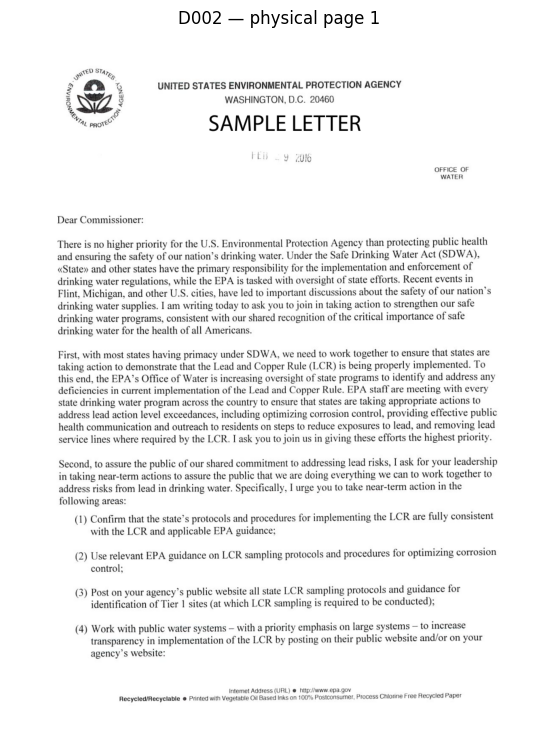

In [5]:
record_image = Image.open(BytesIO(page_record["page_image_png"]))
fig, ax = plt.subplots(figsize=(6, 7.5))
ax.imshow(record_image)
ax.set_title(f"{page_record['doc_id']} — physical page {page_record['page_number']}")
ax.axis("off")
plt.tight_layout()
plt.show()

## Validation

In [6]:
assert len(hybrid_text.split()) > len(native_text.split())
assert "SAMPLE LETTER" in hybrid_text
assert page_record["extraction_method"] == "HYBRID"
assert page_record["page_number"] >= 1
assert page_record["page_image_png"].startswith(b"\x89PNG")
assert page_record["text"] is not None

print("OCR comparison and page-record invariants are valid.")

OCR comparison and page-record invariants are valid.


## Next step

`05_annotations_and_quality.ipynb` checks whether the evaluation metadata is ready to measure retrieval and answer quality.